# BRFSS 2015 — Least Squares and Ridge Regression

We compare Least Squares and Ridge using positive-class F1.

**80/20 protocol aligned with the SGD notebook:** raw observations are split using `split_train_validation()` from `validation.py` (seed 1). Thresholds are selected on training scores using `best_threshold()` from `validation.py`, which tests 50 score quantiles. All metrics are measured on the entire 20% validation portion.

Ridge lambda is selected by validation F1, just as SGD settings are explored on validation data. Consequently, the selected Ridge validation score is a tuning result, not an independent final test estimate. There is no separate calibration or evaluation subset. The competition test set is not used for model or threshold selection.


## 1. Imports & configuration

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from preprocessing import load_feature_names
from implementations import (
    least_squares,
    ridge_regression
)
from helpers import load_csv_data
from preprocessing import load_feature_names, clean_and_standardize
from validation import split_train_validation, best_threshold


def show_table(rows):
    """Print an aligned table without changing the underlying values."""
    if not rows:
        return

    columns = list(rows[0])

    def format_value(value):
        if isinstance(value, (float, np.floating)):
            if np.isnan(value):
                return "—"
            if value != 0 and abs(value) < 1e-3:
                return f"{value:.4e}"
            return f"{value:.4f}"
        return str(value)

    formatted_rows = [
        [format_value(row[column]) for column in columns]
        for row in rows
    ]

    widths = [
        max(len(str(column)), max(len(row[i]) for row in formatted_rows))
        for i, column in enumerate(columns)
    ]

    def format_row(values):
        return " | ".join(
            value.ljust(width) if i == 0 else value.rjust(width)
            for i, (value, width) in enumerate(zip(values, widths))
        )

    print(format_row([str(column) for column in columns]))
    print("-+-".join("-" * width for width in widths))

    for row in formatted_rows:
        print(format_row(row))




def table_column(rows, key):
    return np.array([row[key] for row in rows])


def pivoted_qr_numpy(matrix):
    """Return R and column pivots with NumPy.

    First reduce the tall input with an orthogonal QR transformation. Column
    pivoting then uses Householder reflections on the small reduced matrix.
    Orthogonal reduction preserves column norms and linear dependence, without
    forming X.T @ X (which would square the condition number).
    """
    r = np.linalg.qr(np.asarray(matrix, dtype=float), mode="r")
    pivots = np.arange(r.shape[1])
    for k in range(min(r.shape)):
        norms = np.linalg.norm(r[k:, k:], axis=0)
        pivot = k + int(np.argmax(norms))
        r[:, [k, pivot]] = r[:, [pivot, k]]
        pivots[[k, pivot]] = pivots[[pivot, k]]
        vector = r[k:, k].copy()
        norm = np.linalg.norm(vector)
        if norm == 0:
            continue
        alpha = -np.copysign(norm, vector[0])
        vector[0] -= alpha
        vector /= np.linalg.norm(vector)
        block = r[k:, k:]
        block -= 2 * np.outer(vector, vector @ block)
        r[k, k] = alpha
        r[k + 1:, k] = 0
    return r, pivots


## 2. Prepare data
Preprocessing handles imputation, encoding, and standardization. No observations are removed.

In [18]:
# Load data
data_path = "data"
x, x_test, y, _, test_ids = load_csv_data(data_path)

# Load feature names
names = load_feature_names(data_path)

# Split raw data using the shared validation helper (80% / 20%, seed 1).
X_train_raw, X_val_raw, y_train, y_val = split_train_validation(y, x)

X_train, X_val = clean_and_standardize(
    X_train_raw,
    X_val_raw,
    names,
    one_hot=True
)

## 3. Training and validation subsets
The 80% training portion is used to fit weights, preprocessing and decision thresholds. The full 20% validation portion is used to compare models and tune Ridge lambda. This matches the split and threshold-selection procedure in `sgd_tests.ipynb`.


In [19]:
print("Training:", X_train.shape, "positive fraction:", np.mean(y_train == 1))
print("Validation:", X_val.shape, "positive fraction:", np.mean(y_val == 1))


Training: (262508, 420) positive fraction: 0.08805064988495588
Validation: (65627, 420) positive fraction: 0.08930775443034117


## 4. Metrics

**Important:** LS/Ridge models predict a **continuous score**, not directly −1/+1. We classify an instance as `+1` if `score >= threshold`, and as `−1` otherwise. A threshold of 0 is natural for −1/+1 targets, but it is **not necessarily optimal for the F1 score**.

In [30]:
def predict_labels(scores, threshold=0.0):
    return np.where(np.asarray(scores) >= threshold, 1, -1)


def classification_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == -1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == -1)))
    tn = int(np.sum((y_true == -1) & (y_pred == -1)))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    accuracy = (tp + tn) / len(y_true)
    return dict(F1=f1, Precision=precision, Recall=recall,
                Accuracy=accuracy, TP=tp, FP=fp, FN=fn, TN=tn)

## 5. Least Squares

In [31]:
# Identify independent columns using training data only.
R, piv = pivoted_qr_numpy(X_train)
singular_values = np.linalg.svd(R, compute_uv=False)
tolerance = singular_values.max() * max(X_train.shape) * np.finfo(float).eps
rank = int(np.sum(singular_values > tolerance))
independent_cols = piv[:rank]
dependent_cols = piv[rank:]

X_train_fixed = X_train[:, independent_cols]
X_val_fixed = X_val[:, independent_cols]
w_ls, ls_train_loss = least_squares(y_train.astype(float), X_train_fixed)

# Use the same training-based quantile search as the SGD notebook.
ls_train_scores = X_train_fixed @ w_ls
ls_val_scores = X_val_fixed @ w_ls
ls_threshold = best_threshold(y_train, ls_train_scores)
ls_val_default = classification_metrics(y_val, predict_labels(ls_val_scores, 0.0))
ls_val_tuned = classification_metrics(y_val, predict_labels(ls_val_scores, ls_threshold))

print(f"Least Squares: training half-MSE = {ls_train_loss:.5f}; "
      f"training-selected threshold = {ls_threshold:.5f}")
ls_rows = [
    {"Model": "LS, threshold 0", **ls_val_default},
    {"Model": "LS, training-selected threshold", **ls_val_tuned},
]
show_table(ls_rows)


Least Squares: training half-MSE = 0.13240; training-selected threshold = -0.55152
Model                           |     F1 | Precision | Recall | Accuracy |   TP |   FP |   FN |    TN
--------------------------------+--------+-----------+--------+----------+------+------+------+------
LS, threshold 0                 | 0.1008 |    0.6517 | 0.0546 |   0.9130 |  320 |  171 | 5541 | 59595
LS, training-selected threshold | 0.4245 |    0.3558 | 0.5260 |   0.8726 | 3083 | 5581 | 2778 | 54185


## 6. Ridge Regression


In [32]:
n_train, n_features = X_train.shape
ridge_gram = X_train.T @ X_train
ridge_rhs = X_train.T @ y_train.astype(float)
lambdas = np.logspace(-6, 2, 30)
results = []
ridge_weights = {}
ridge_thresholds = {}

for lam in lambdas:
    w = np.linalg.solve(
        ridge_gram + 2 * n_train * lam * np.identity(n_features), ridge_rhs
    )
    ridge_weights[float(lam)] = w
    train_scores = X_train @ w
    threshold = best_threshold(y_train, train_scores)
    ridge_thresholds[float(lam)] = threshold
    val_scores = X_val @ w
    at_zero = classification_metrics(y_val, predict_labels(val_scores, 0.0))
    tuned = classification_metrics(y_val, predict_labels(val_scores, threshold))
    results.append({
        "lambda": float(lam),
        "F1_val_threshold_0": at_zero["F1"],
        "F1_val_training_threshold": tuned["F1"],
        "precision_val": tuned["Precision"],
        "recall_val": tuned["Recall"],
        "threshold": threshold,
        "weight_norm": np.linalg.norm(w),
        "MSE_val": np.mean((y_val - val_scores) ** 2),
    })

ridge_df = results
# Validation is used for lambda selection; this score is a tuning result.
best_row = max(ridge_df, key=lambda row: row["F1_val_training_threshold"])
best_lambda = float(best_row["lambda"])
best_ridge_threshold = ridge_thresholds[best_lambda]
print(f"Best lambda (validation tuning) = {best_lambda:.6g}")
print(f"Training-selected threshold = {best_ridge_threshold:.6f}")
print(f"Validation F1 (used for lambda selection) = {best_row['F1_val_training_threshold']:.4f}")
show_table(ridge_df)


Best lambda (validation tuning) = 1e-06
Training-selected threshold = -0.568341
Validation F1 (used for lambda selection) = 0.4258
lambda     | F1_val_threshold_0 | F1_val_training_threshold | precision_val | recall_val | threshold | weight_norm | MSE_val
-----------+--------------------+---------------------------+---------------+------------+-----------+-------------+--------
1.0000e-06 |             0.1004 |                    0.4258 |        0.3465 |     0.5520 |   -0.5683 |      4.1898 |  0.2676
1.8874e-06 |             0.1002 |                    0.4254 |        0.3461 |     0.5518 |   -0.5685 |      4.0905 |  0.2676
3.5622e-06 |             0.1007 |                    0.4248 |        0.3455 |     0.5513 |   -0.5689 |      3.9258 |  0.2676
6.7234e-06 |             0.1004 |                    0.4235 |        0.3549 |     0.5252 |   -0.5528 |      3.6578 |  0.2676
1.2690e-05 |             0.0984 |                    0.4245 |        0.3555 |     0.5265 |   -0.5536 |      3.2528 |  0

## 7. Comparison on the full validation subset
Thresholds are fitted on the training portion. The table reports metrics on all 20% validation observations. Ridge lambda is selected using these validation scores, so its selected score is not an independent test estimate.


In [33]:
best_w = ridge_weights[best_lambda]
ridge_val_scores = X_val @ best_w

rows = [
    {
        "Model": "Least Squares / threshold 0",
        "lambda": 0.0,
        "threshold": 0.0,
        **ls_val_default,
    },
    {
        "Model": "Least Squares / training-selected threshold",
        "lambda": 0.0,
        "threshold": ls_threshold,
        **ls_val_tuned,
    },
    {
        "Model": "Ridge / threshold 0",
        "lambda": best_lambda,
        "threshold": 0.0,
        **classification_metrics(
            y_val, predict_labels(ridge_val_scores, 0.0)
        ),
    },
    {
        "Model": "Ridge / training-selected threshold",
        "lambda": best_lambda,
        "threshold": best_ridge_threshold,
        **classification_metrics(
            y_val, predict_labels(ridge_val_scores, best_ridge_threshold)
        ),
    },
]

comparison = rows
show_table(comparison)


Model                                       |     lambda | threshold |     F1 | Precision | Recall | Accuracy |   TP |   FP |   FN |    TN
--------------------------------------------+------------+-----------+--------+-----------+--------+----------+------+------+------+------
Least Squares / threshold 0                 |     0.0000 |    0.0000 | 0.1008 |    0.6517 | 0.0546 |   0.9130 |  320 |  171 | 5541 | 59595
Least Squares / training-selected threshold |     0.0000 |   -0.5515 | 0.4245 |    0.3558 | 0.5260 |   0.8726 | 3083 | 5581 | 2778 | 54185
Ridge / threshold 0                         | 1.0000e-06 |    0.0000 | 0.1004 |    0.6484 | 0.0544 |   0.9129 |  319 |  173 | 5542 | 59593
Ridge / training-selected threshold         | 1.0000e-06 |   -0.5683 | 0.4258 |    0.3465 | 0.5520 |   0.8670 | 3235 | 6100 | 2626 | 53666


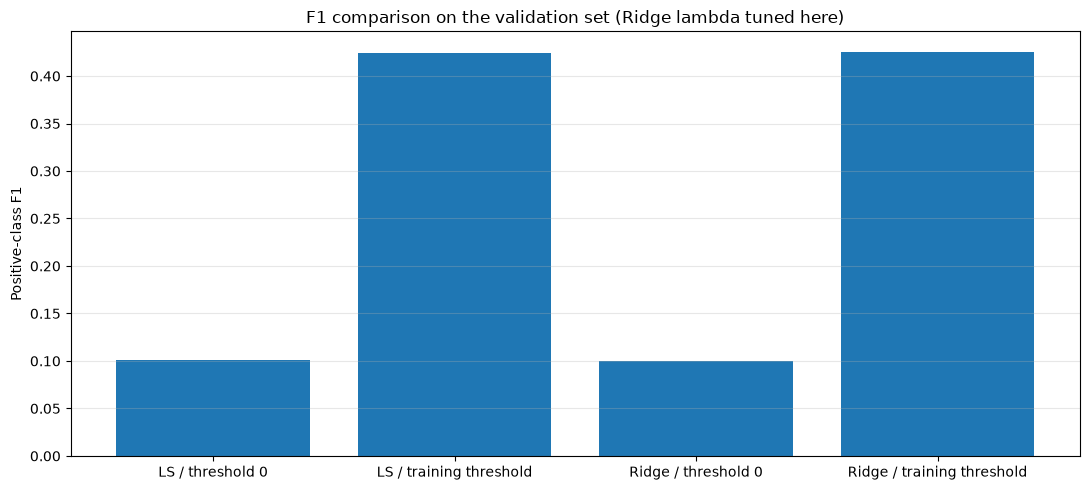

In [34]:
fig, ax = plt.subplots(figsize=(11, 5))

model_names = [
    "Least Squares / threshold 0",
    "Least Squares / training-selected threshold",
    "Ridge / threshold 0",
    "Ridge / training-selected threshold",
]
by_name = {row["Model"]: row for row in comparison}
subset = [by_name[name] for name in model_names]

ax.bar(np.arange(len(subset)), table_column(subset, "F1"))
ax.set_xticks(
    np.arange(len(subset)),
    ["LS / threshold 0", "LS / training threshold", "Ridge / threshold 0", "Ridge / training threshold"],
)
ax.set_ylabel("Positive-class F1")
ax.set_title("F1 comparison on the validation set (Ridge lambda tuned here)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()